In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

In [2]:
# Pregunta 1: Importar el conjunto de datos con Pandas
df = pd.read_csv("Life_Expectancy_Data.csv")
df.columns = df.columns.str.strip()
df.head()

,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [3]:
# Pregunta 2: Comprobar valores perdidos
df.isnull().sum()

Year                                 0
Status                               0
Life expectancy                     10
Adult Mortality                     10
infant deaths                        0
Alcohol                            194
percentage expenditure               0
Hepatitis B                        553
Measles                              0
BMI                                 34
under-five deaths                    0
Polio                               19
Total expenditure                  226
Diphtheria                          19
HIV/AIDS                             0
GDP                                448
Population                         652
thinness  1-19 years                34
thinness 5-9 years                  34
Income composition of resources    167
Schooling                          163
dtype: int64

In [4]:
# Pregunta 2: Ingeniería de variables (eliminar / rellenar valores perdidos)
df = df.dropna(subset=["Life expectancy"])

cols_cero = ["Income composition of resources", "Schooling"]
df[cols_cero] = df[cols_cero].replace(0, np.nan)

num_cols = df.select_dtypes(include="number").columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

df.isnull().sum().sum()

np.int64(0)

In [5]:
# Pregunta 3: Uso de memoria del DataFrame
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
Index: 2928 entries, 0 to 2937
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Year                             2928 non-null   int64  
 1   Status                           2928 non-null   str    
 2   Life expectancy                  2928 non-null   float64
 3   Adult Mortality                  2928 non-null   float64
 4   infant deaths                    2928 non-null   int64  
 5   Alcohol                          2928 non-null   float64
 6   percentage expenditure           2928 non-null   float64
 7   Hepatitis B                      2928 non-null   float64
 8   Measles                          2928 non-null   int64  
 9   BMI                              2928 non-null   float64
 10  under-five deaths                2928 non-null   int64  
 11  Polio                            2928 non-null   float64
 12  Total expenditure                292

In [6]:
# Pregunta 4: Esperanza de vida mínima, media y máxima
df["Life expectancy"].agg(["min", "mean", "max"])

min     36.300000
mean    69.224932
max     89.000000
Name: Life expectancy, dtype: float64

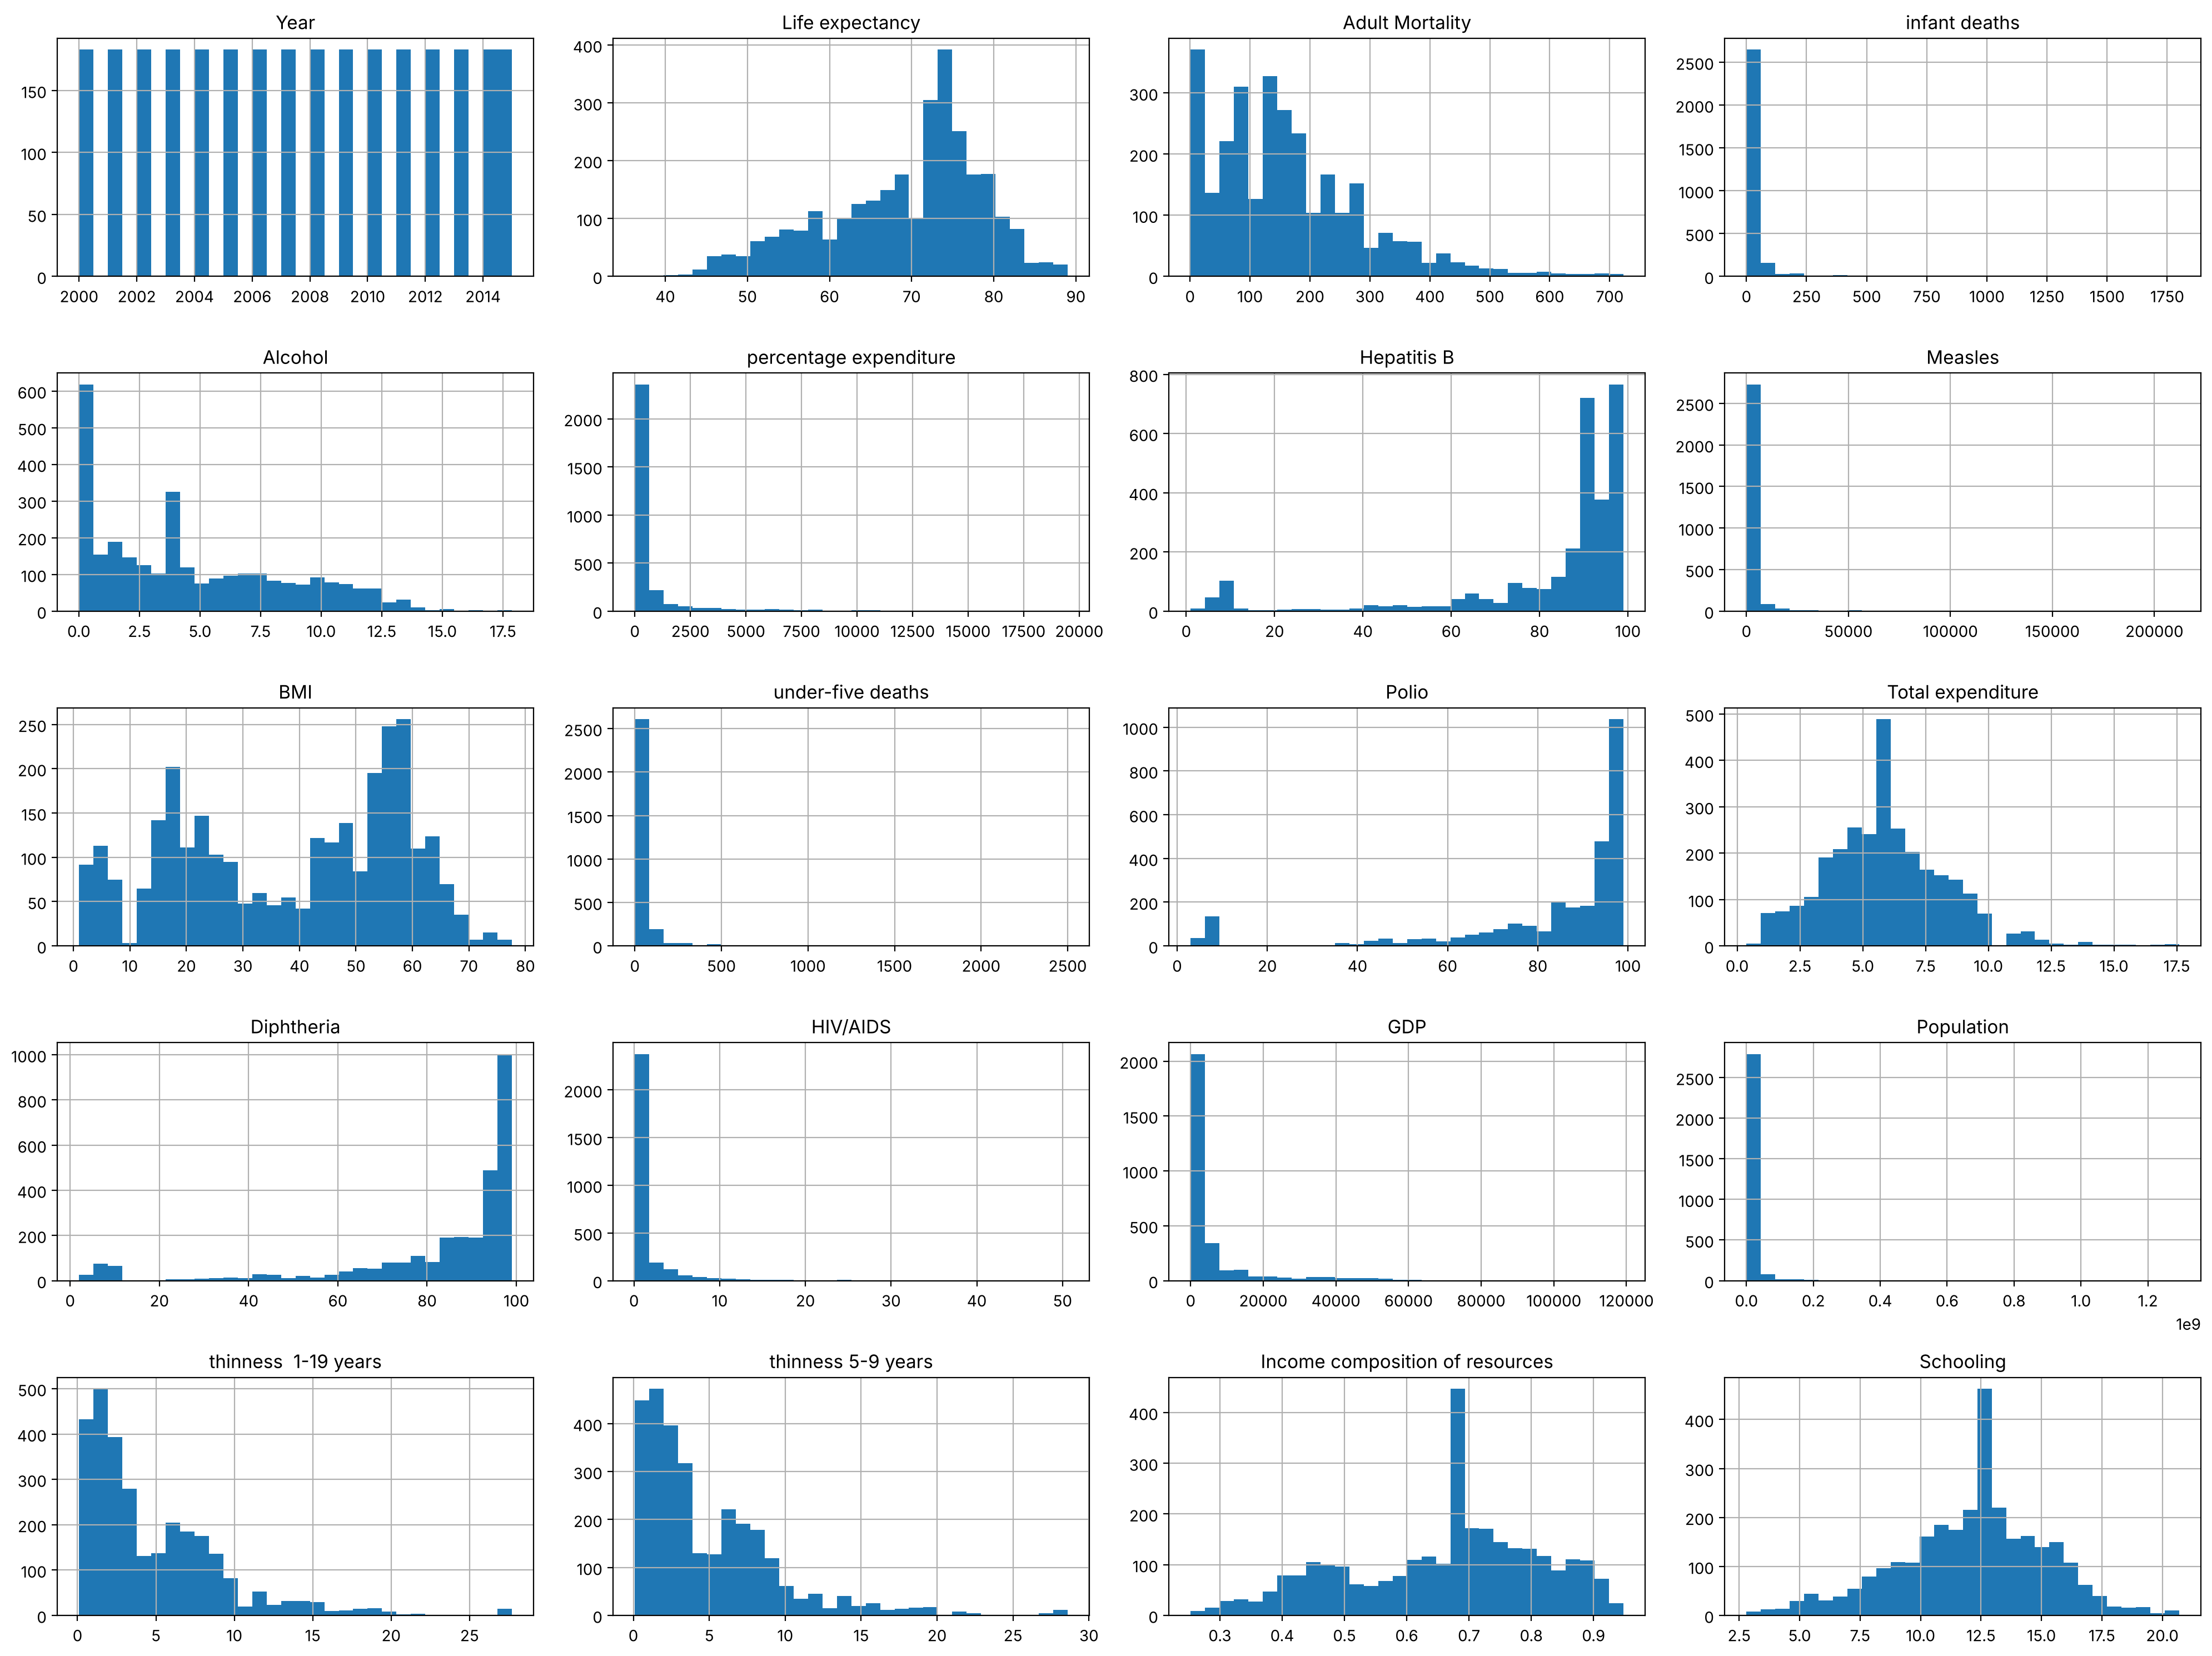

In [7]:
# Pregunta 5: Histograma
df.hist(bins=30, figsize=(20, 15))
plt.tight_layout()
plt.show()

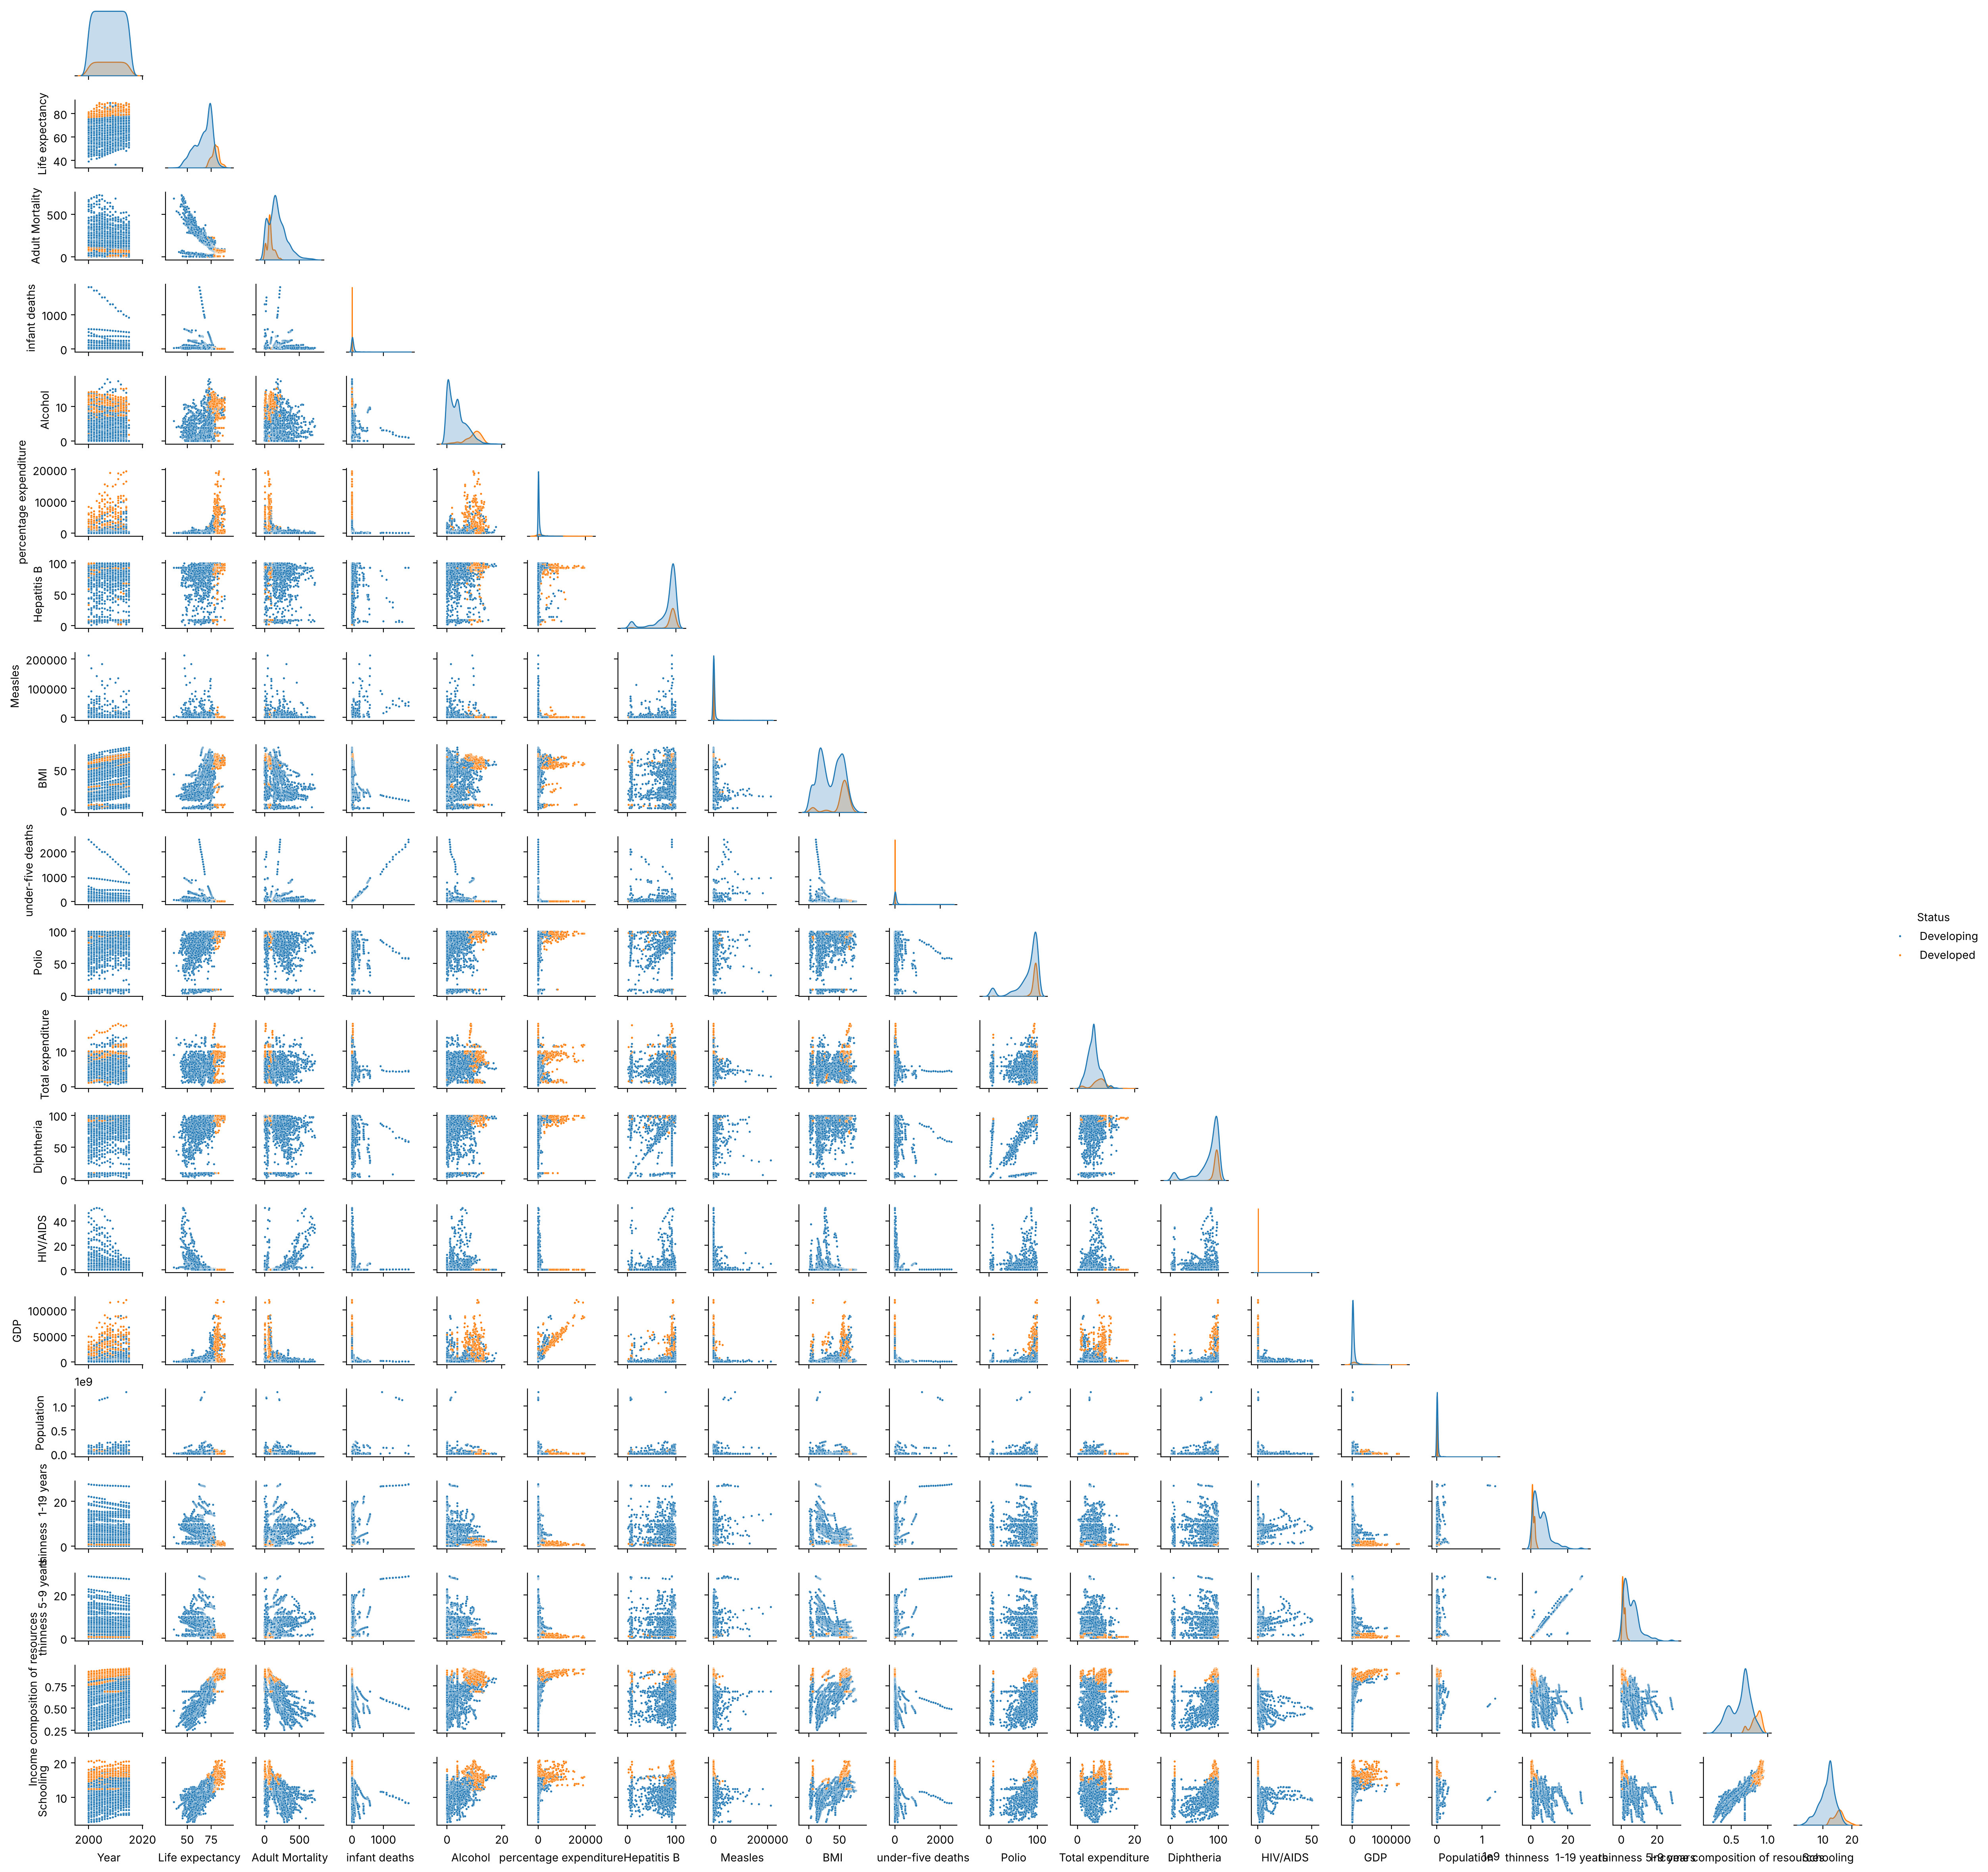

In [8]:
# Pregunta 5: Diagrama de pares
sns.pairplot(df, hue="Status", height=1.2, corner=True, plot_kws={"s": 4})
plt.show()

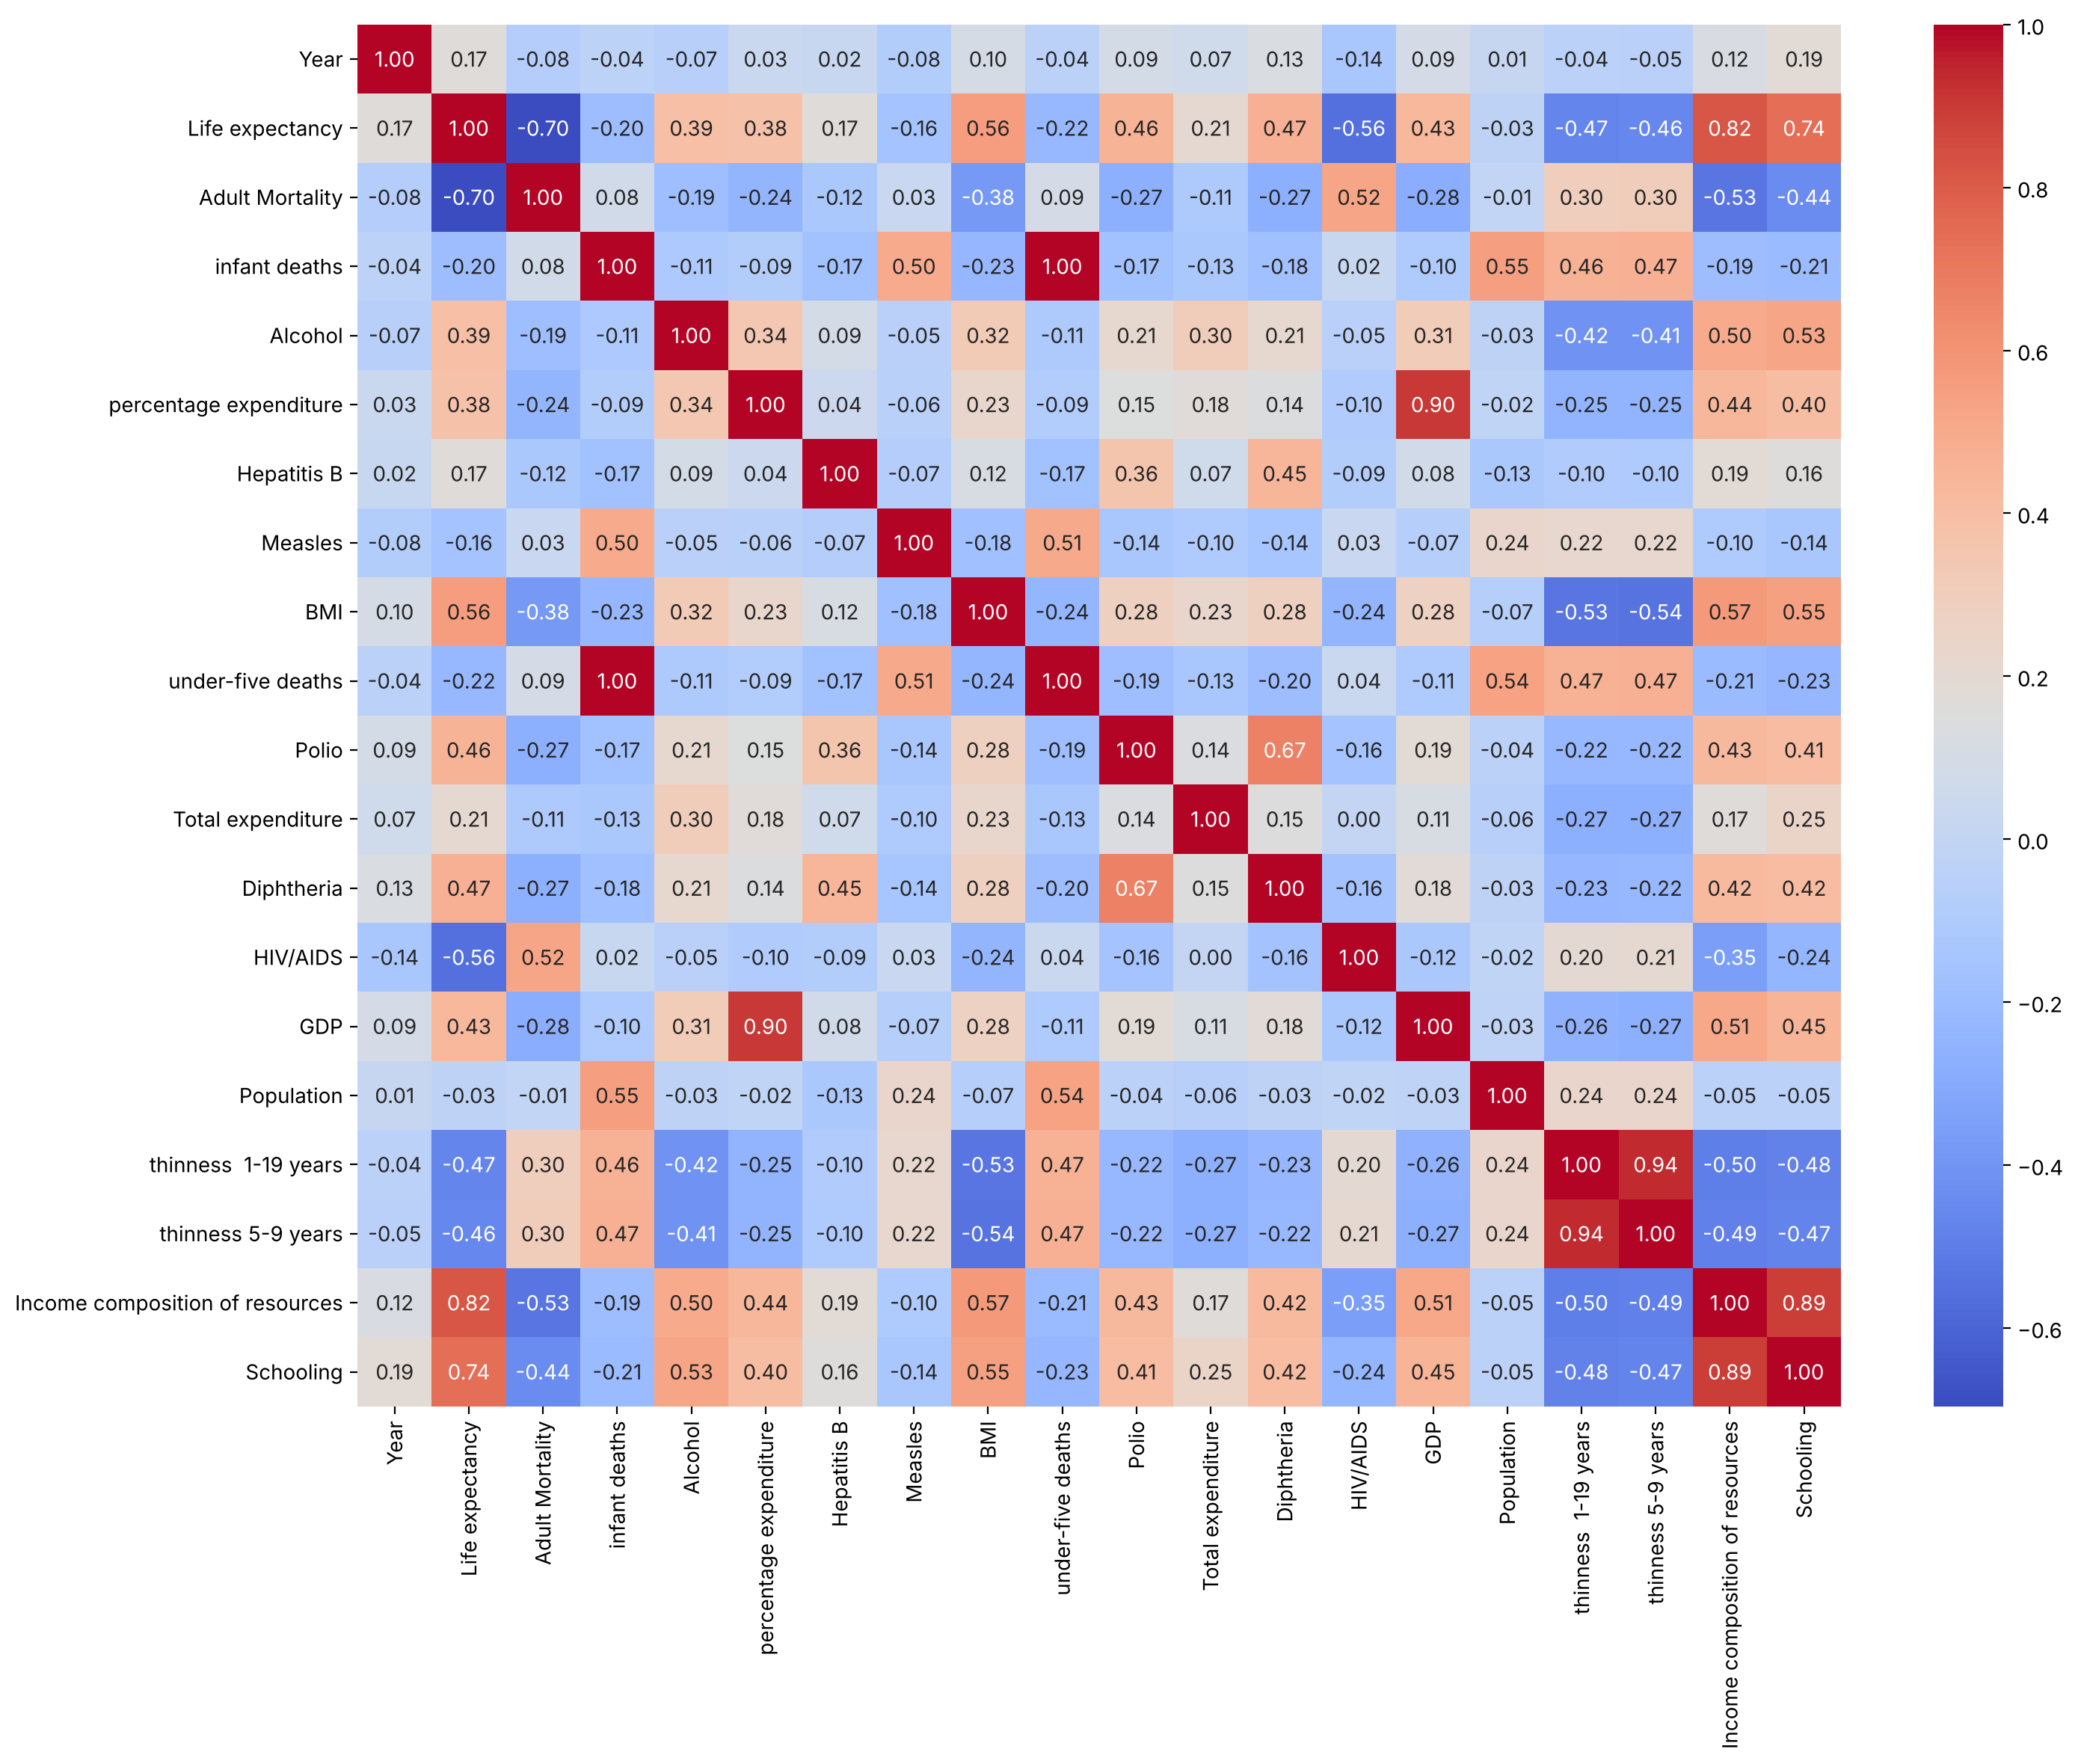

In [9]:
# Pregunta 5: Mapa de correlación
plt.figure(figsize=(16, 12))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

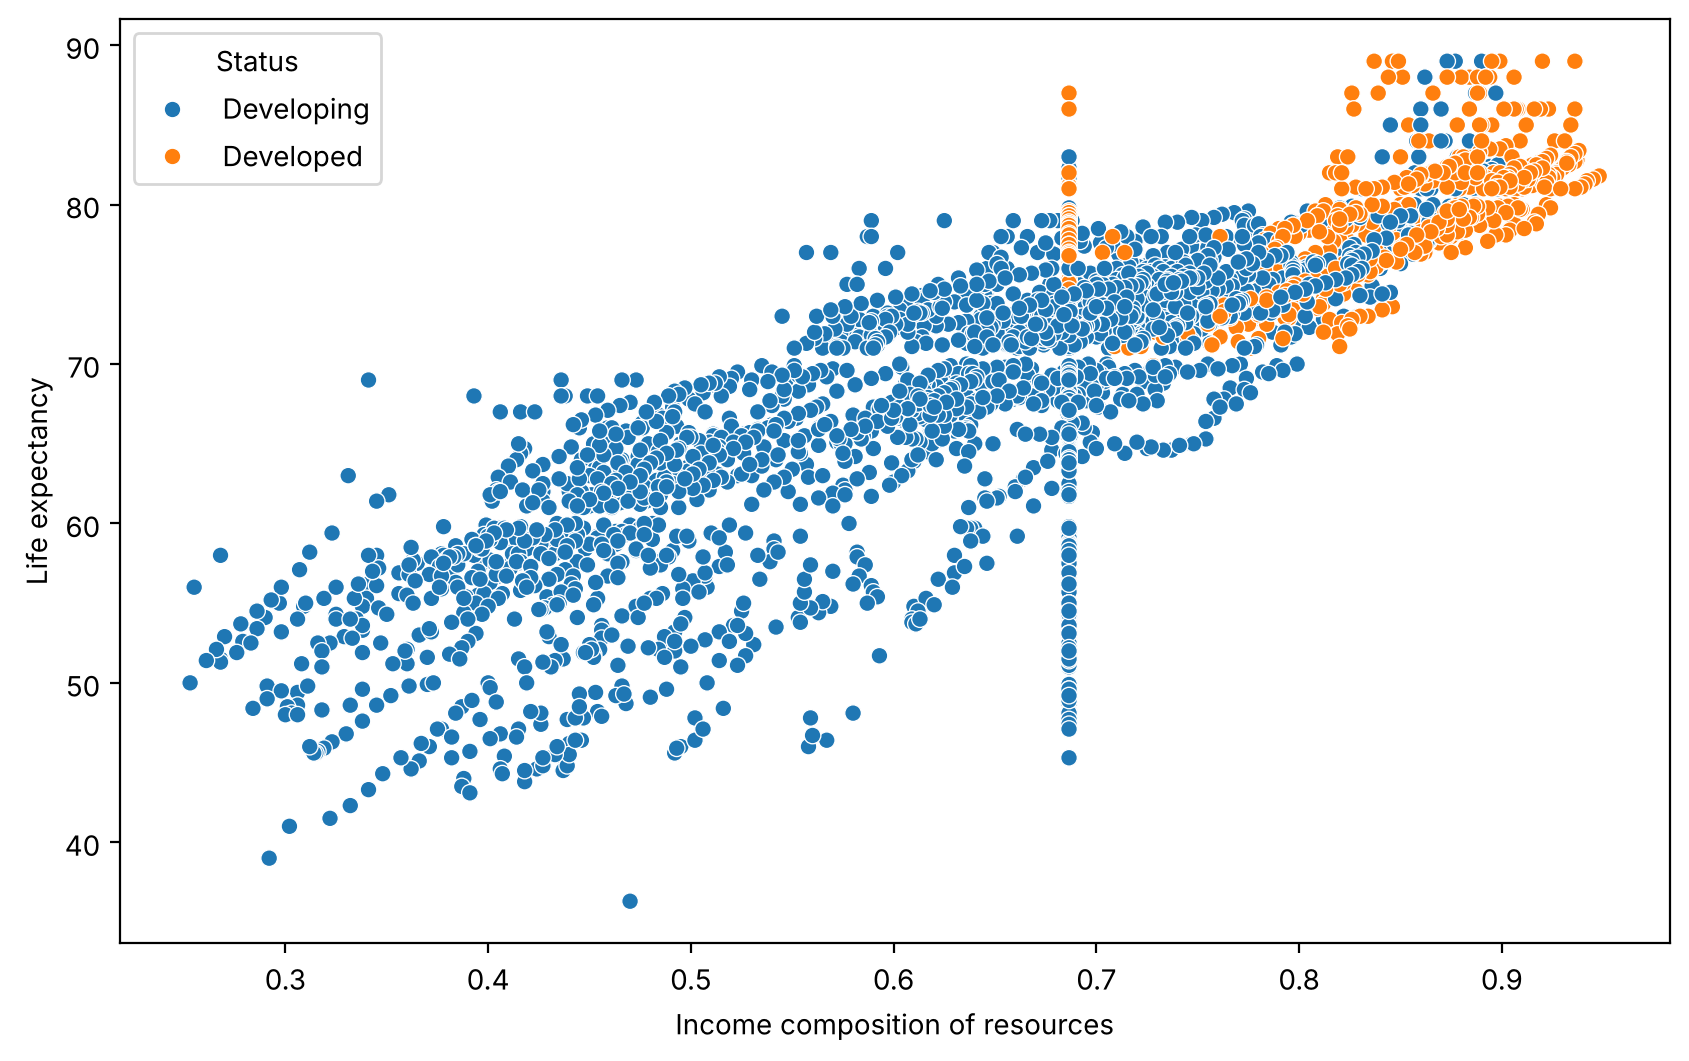

In [10]:
# Pregunta 6: Dispersión Composición de ingresos de los recursos vs Esperanza de vida
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Income composition of resources", y="Life expectancy", hue="Status")
plt.show()

# Comentario: relación positiva y fuerte (correlación ≈ 0.82): a mayor composición de ingresos,
# mayor esperanza de vida. Los países desarrollados se concentran arriba a la derecha
# (índice ≈ 0.76-0.92 y esperanza de vida de 70 años o más); los países en desarrollo están
# mucho más dispersos (índice desde 0.25 y esperanza de vida desde 36 años).
# La línea vertical en ≈ 0.69 son los valores perdidos rellenados con la mediana.

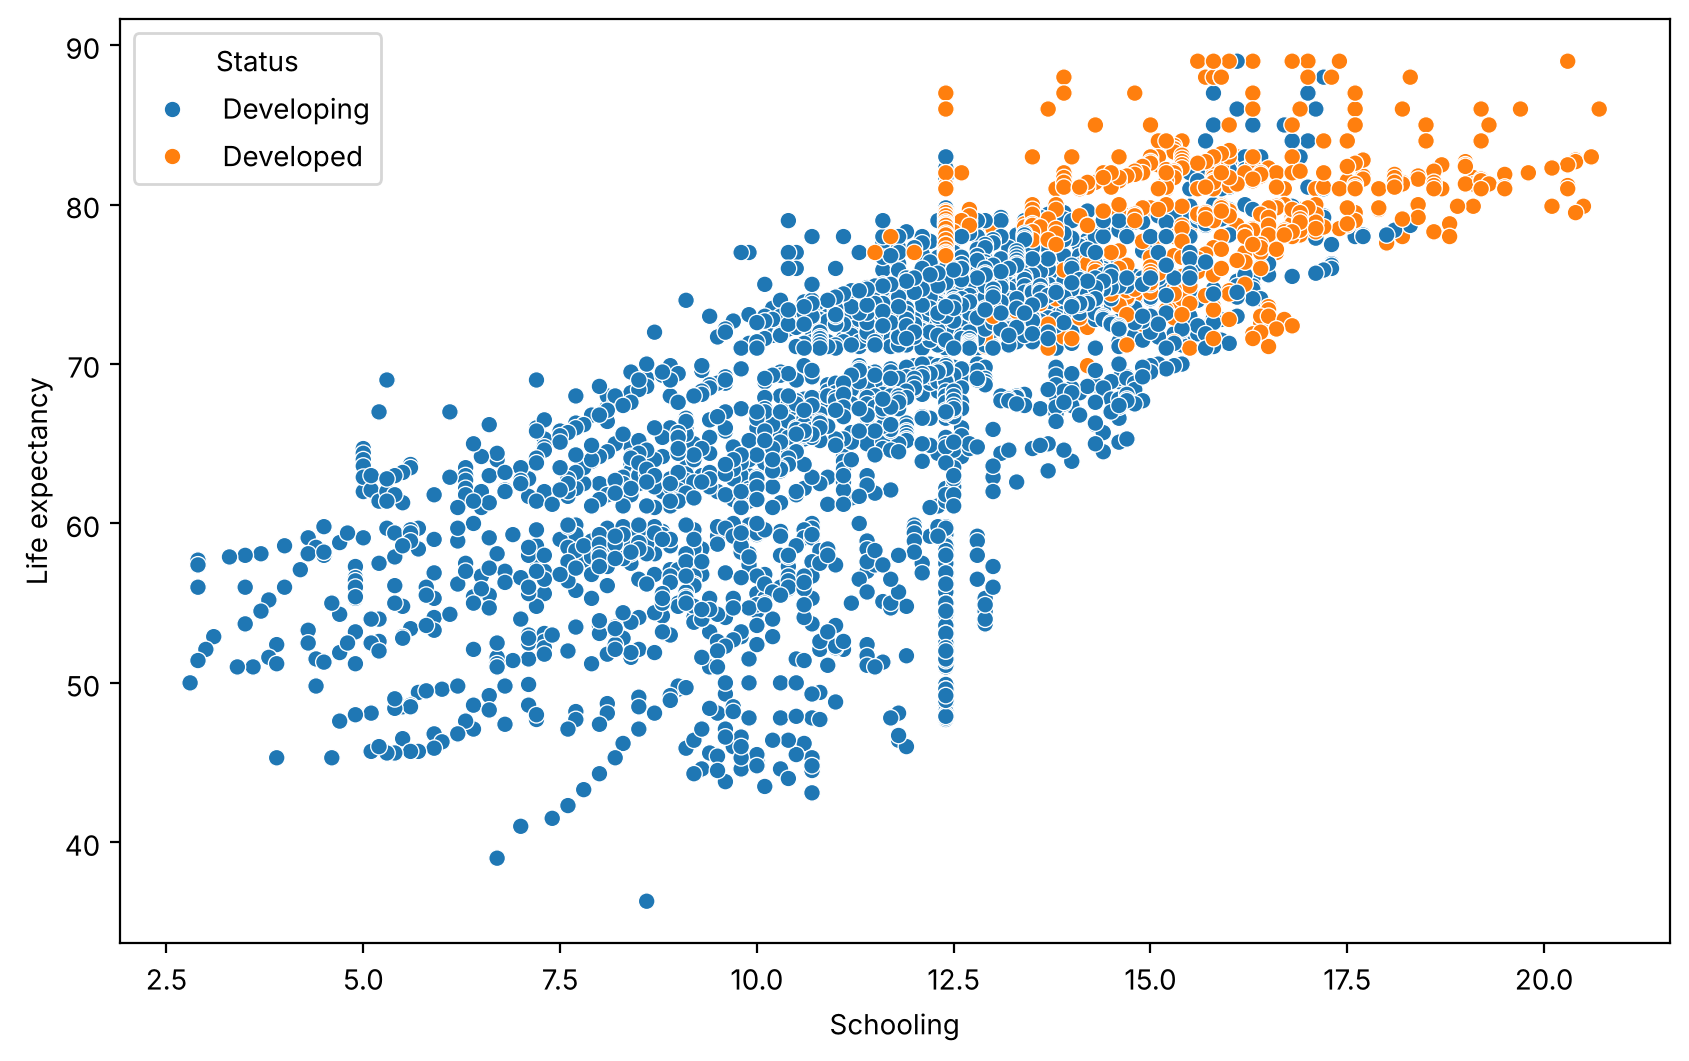

In [11]:
# Pregunta 7: Dispersión Escolarización vs Esperanza de vida
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Schooling", y="Life expectancy", hue="Status")
plt.show()

# Comentario: relación positiva (correlación ≈ 0.74): más años de escolarización se asocian a
# mayor esperanza de vida, aunque con más dispersión que en la pregunta 6. Los países desarrollados
# tienen en su mayoría entre 13 y 19 años de escolarización y esperanza de vida mayor a 72 años;
# en los países en desarrollo con menos de 10 años de escolarización, la mayoría está por debajo de 60.
# La línea vertical en ≈ 12.4 son los valores perdidos rellenados con la mediana.

In [12]:
# Pregunta 8: División 80% entrenamiento / 20% prueba
df["Status"] = df["Status"].map({"Developing": 0, "Developed": 1})

X = df.drop(columns="Life expectancy")
y = df["Life expectancy"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(2342, 20) (586, 20)


In [13]:
# Pregunta 9: Entrenar algoritmo XGBoost
model = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, random_state=42)
model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [14]:
# Pregunta 10: Evaluar el rendimiento del modelo (R2)
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R2:   {r2:.4f}")
print(f"MAE:  {mae:.2f} años")
print(f"RMSE: {rmse:.2f} años")

R2:   0.9670
MAE:  1.07 años
RMSE: 1.69 años


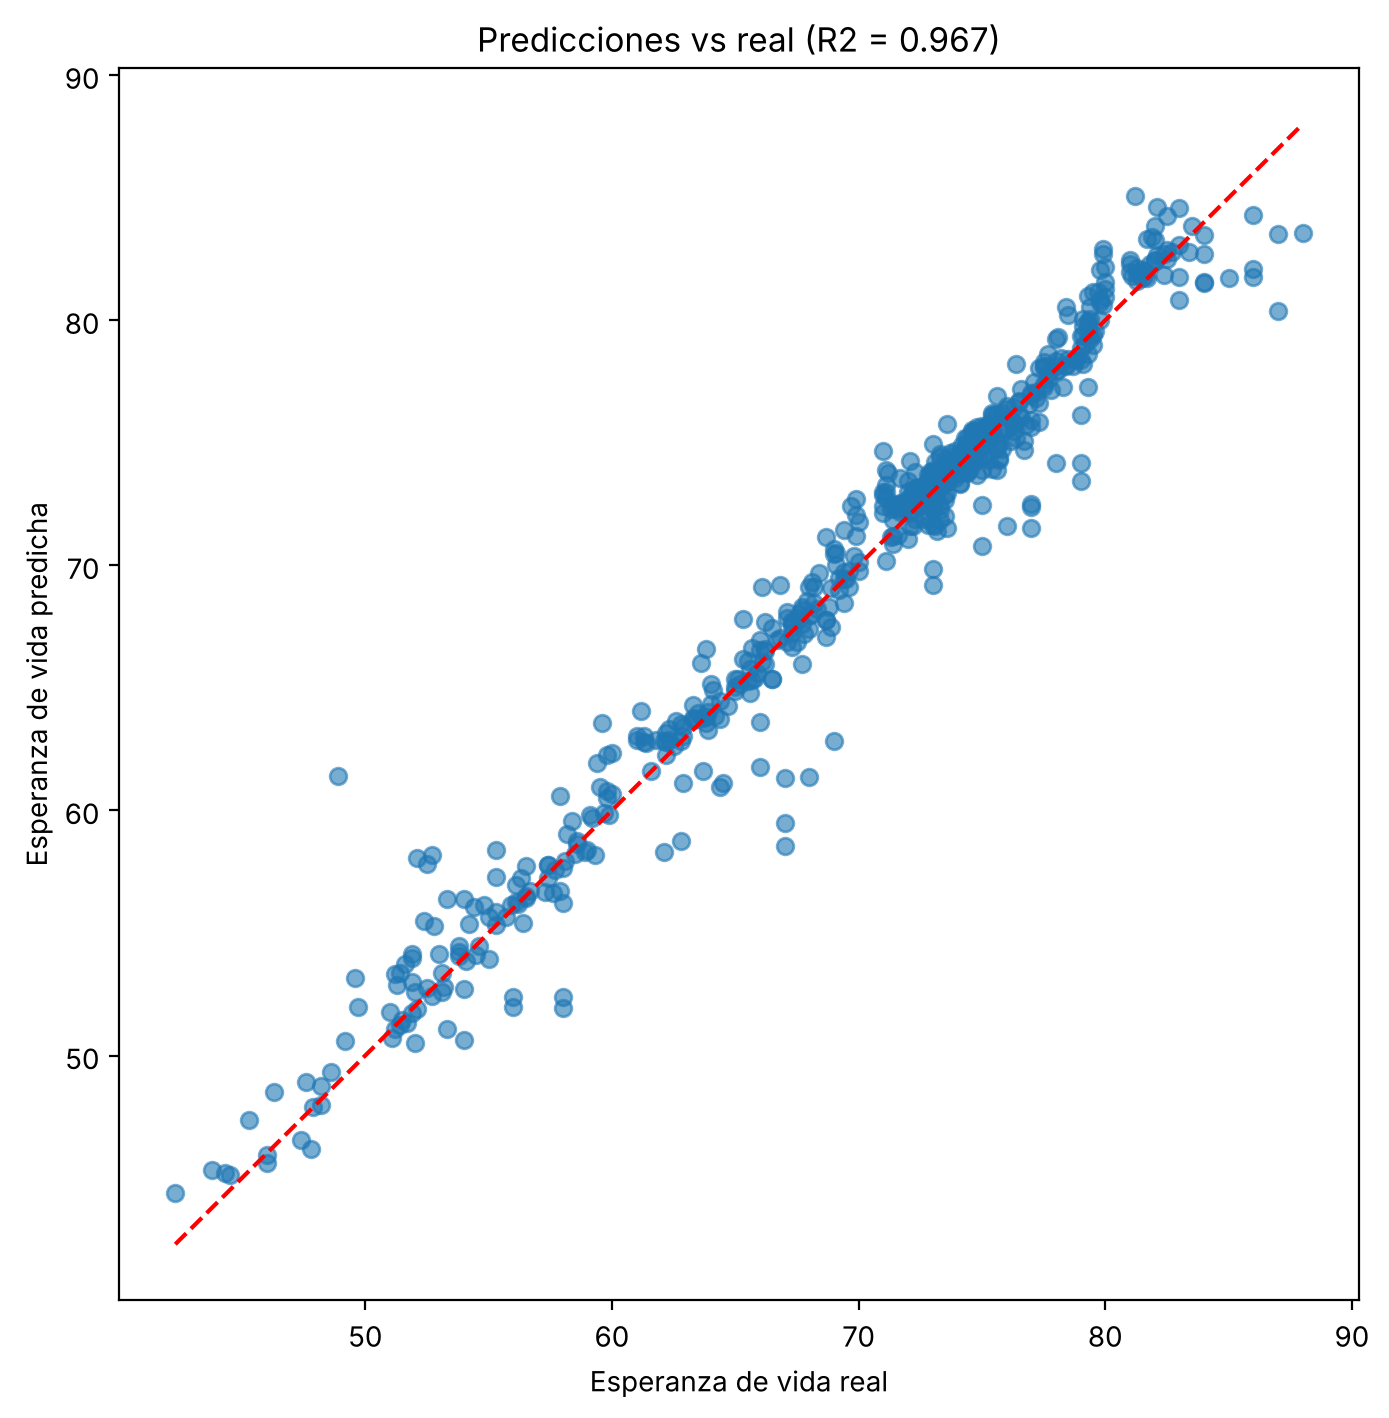

In [15]:
# Pregunta 11: Predicciones del modelo vs resultado real
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Esperanza de vida real")
plt.ylabel("Esperanza de vida predicha")
plt.title(f"Predicciones vs real (R2 = {r2:.3f})")
plt.show()